In [1]:
import pandas as pd

# 读取 CSV，当前先按文本保留各字段
df = pd.read_csv(
    "dpe_lyon_raw.csv",
    encoding="utf-8-sig",
    dtype=str
)

# 显示数据行数和列数
print("数据行数：", df.shape[0])
print("字段数量：", df.shape[1])

数据行数： 10000
字段数量： 226


In [2]:
# 选择需要查看的列
colonnes_a_verifier = [
    "numero_dpe",
    "nom_commune_ban",
    "type_batiment",
    "surface_habitable_logement",
    "etiquette_dpe",
    "cout_total_5_usages"
]

# 显示这六列的前五行
df[colonnes_a_verifier].head()

,numero_dpe,nom_commune_ban,type_batiment,surface_habitable_logement,etiquette_dpe,cout_total_5_usages
0,2669E0027508W,Lyon,appartement,37.5,C,273.7
1,2669E0062001N,Lyon,appartement,67.5,C,1160.8
2,2669E0019280K,Lyon,appartement,42,D,926.3
3,2669E0045216Y,Lyon,appartement,55,C,984.1
4,2669E0070375P,Lyon,appartement,47.8,D,1297


In [3]:
# 检查数据属于哪些城市
print("—— 城市及记录数量 ——")
print(df["nom_commune_ban"].value_counts(dropna=False))

# 检查建筑类型
print("\n—— 建筑类型及记录数量 ——")
print(df["type_batiment"].value_counts(dropna=False))

# 检查关键字段的缺失数量
colonnes_a_controler = [
    "etiquette_dpe",
    "cout_total_5_usages",
    "surface_habitable_logement"
]

print("\n—— 关键字段缺失数量 ——")
print(df[colonnes_a_controler].isna().sum())

—— 城市及记录数量 ——
nom_commune_ban
Lyon    10000
Name: count, dtype: int64

—— 建筑类型及记录数量 ——
type_batiment
appartement    9667
maison          254
immeuble         79
Name: count, dtype: int64

—— 关键字段缺失数量 ——
etiquette_dpe                   0
cout_total_5_usages             2
surface_habitable_logement    143
dtype: int64


In [4]:
df_clean = df.loc[
    df["type_batiment"].isin(["appartement", "maison"])
].copy()

print("Nombre initial :", len(df))
print("Nombre conservé :", len(df_clean))
print("Nombre exclu :", len(df) - len(df_clean))

print("\nValeurs manquantes après filtrage :")
print(
    df_clean[
        [
            "etiquette_dpe",
            "cout_total_5_usages",
            "surface_habitable_logement"
        ]
    ].isna().sum()
)

Nombre initial : 10000
Nombre conservé : 9921
Nombre exclu : 79

Valeurs manquantes après filtrage :
etiquette_dpe                  0
cout_total_5_usages            2
surface_habitable_logement    65
dtype: int64


In [5]:
anciennes_colonnes = df_clean.columns.copy()

nouvelles_colonnes = (
    anciennes_colonnes
    .str.strip()
    .str.replace(r"\s+", "_", regex=True)
)

if nouvelles_colonnes.duplicated().any():
    raise ValueError("Des noms de colonnes deviennent identiques.")

df_clean.columns = nouvelles_colonnes

modifications = [
    (ancien, nouveau)
    for ancien, nouveau in zip(anciennes_colonnes, nouvelles_colonnes)
    if ancien != nouveau
]

print("Nombre de colonnes renommées :", len(modifications))

for ancien, nouveau in modifications:
    print(f"{ancien!r} -> {nouveau!r}")

print("\nDimensions :", df_clean.shape)

Nombre de colonnes renommées : 8
'qualite_isolation_plancher bas' -> 'qualite_isolation_plancher_bas'
'conso_5 usages_ef' -> 'conso_5_usages_ef'
'conso_5 usages_par_m2_ef' -> 'conso_5_usages_par_m2_ef'
'emission_ges_5_usages par_m2' -> 'emission_ges_5_usages_par_m2'
'conso_5 usages_ef_energie_n1' -> 'conso_5_usages_ef_energie_n1'
'conso_5 usages_ef_energie_n2' -> 'conso_5_usages_ef_energie_n2'
'cout_total_5_usages energie_n3' -> 'cout_total_5_usages_energie_n3'
' nombre_logements_desservis_par_installation_ecs_n1' -> 'nombre_logements_desservis_par_installation_ecs_n1'

Dimensions : (9921, 226)


In [6]:
print("Modèles de DPE :")
print(df_clean["modele_dpe"].value_counts(dropna=False))

print("\nMéthodes d'application :")
print(df_clean["methode_application_dpe"].value_counts(dropna=False))

Modèles de DPE :
modele_dpe
DPE 3CL 2021 méthode logement    9921
Name: count, dtype: int64

Méthodes d'application :
methode_application_dpe
dpe appartement individuel                                  9091
dpe appartement généré à partir des données DPE immeuble     576
dpe maison individuelle                                      254
Name: count, dtype: int64


In [7]:
print("Lignes entièrement identiques :")
print(df_clean.duplicated().sum())

print("\nNuméros de DPE manquants :")
print(df_clean["numero_dpe"].isna().sum())

print("\nDoublons de numero_dpe :")
print(df_clean["numero_dpe"].duplicated().sum())

doublons_dpe = df_clean.loc[
    df_clean["numero_dpe"].duplicated(keep=False),
    [
        "numero_dpe",
        "date_etablissement_dpe",
        "date_derniere_modification_dpe",
        "type_batiment"
    ]
]

doublons_dpe.head(10)

Lignes entièrement identiques :
0

Numéros de DPE manquants :
0

Doublons de numero_dpe :
0


,numero_dpe,date_etablissement_dpe,date_derniere_modification_dpe,type_batiment


In [8]:
cible_classification = "etiquette_dpe"
cible_regression = "conso_5_usages_ep"

df_clean[cible_classification] = (
    df_clean[cible_classification]
    .str.strip()
    .str.upper()
)

classes_valides = ["A", "B", "C", "D", "E", "F", "G"]

print("Répartition des étiquettes DPE :")
print(
    df_clean[cible_classification]
    .value_counts(dropna=False)
    .reindex(classes_valides, fill_value=0)
)

masque_classe_invalide = (
    ~df_clean[cible_classification].isin(classes_valides)
)

print(
    "\nÉtiquettes manquantes ou invalides :",
    masque_classe_invalide.sum()
)

Répartition des étiquettes DPE :
etiquette_dpe
A      11
B     264
C    3460
D    3382
E    1806
F     624
G     374
Name: count, dtype: int64

Étiquettes manquantes ou invalides : 0


In [9]:
colonnes_numeriques = [
    "surface_habitable_logement",
    cible_regression
]

for colonne in colonnes_numeriques:
    valeurs_initiales = df_clean[colonne].copy()

    valeurs_converties = pd.to_numeric(
        valeurs_initiales,
        errors="coerce"
    )

    conversions_impossibles = (
        valeurs_initiales.notna()
        & valeurs_converties.isna()
    )

    print(
        f"{colonne} : "
        f"{conversions_impossibles.sum()} conversion(s) impossible(s)"
    )

    df_clean[colonne] = valeurs_converties

print("\nValeurs manquantes :")
print(df_clean[colonnes_numeriques].isna().sum())

print("\nDistribution de la consommation annuelle :")
print(
    df_clean[cible_regression].describe(
        percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
    )
)

surface_habitable_logement : 0 conversion(s) impossible(s)
conso_5_usages_ep : 0 conversion(s) impossible(s)

Valeurs manquantes :
surface_habitable_logement    65
conso_5_usages_ep              1
dtype: int64

Distribution de la consommation annuelle :
count      9920.000000
mean      11786.847974
std        8846.154770
min         312.300000
1%         2449.026000
25%        6810.600000
50%        9877.450000
75%       14779.250000
99%       38846.489000
max      381901.200000
Name: conso_5_usages_ep, dtype: float64


In [10]:
df_classification = df_clean.loc[
    df_clean[cible_classification].isin(classes_valides)
].copy()

df_regression = df_clean.loc[
    df_clean[cible_regression].notna()
].copy()

print("Nombre de lignes pour la classification :")
print(len(df_classification))

print("\nNombre de lignes pour la régression :")
print(len(df_regression))

print("\nAperçu des cibles :")
print(
    df_clean[
        [
            "numero_dpe",
            cible_classification,
            cible_regression
        ]
    ].head()
)

Nombre de lignes pour la classification :
9921

Nombre de lignes pour la régression :
9920

Aperçu des cibles :
      numero_dpe etiquette_dpe  conso_5_usages_ep
0  2669E0027508W             C             2733.8
1  2669E0062001N             C             9015.7
2  2669E0019280K             D             7703.6
3  2669E0045216Y             C             8283.4
4  2669E0070375P             D            11346.5


In [11]:
colonnes_controle = [
    "numero_dpe",
    "type_batiment",
    "surface_habitable_logement",
    "conso_5_usages_ep",
    "conso_5_usages_par_m2_ep",
    "etiquette_dpe",
    "methode_application_dpe"
]

df_regression.sort_values(
    by=cible_regression,
    ascending=False
)[colonnes_controle].head(10)

,numero_dpe,type_batiment,surface_habitable_logement,conso_5_usages_ep,conso_5_usages_par_m2_ep,etiquette_dpe,methode_application_dpe
8492,2169E0807345K,appartement,45.0,381901.2,8486.6,G,dpe appartement individuel
1025,2669E0150396I,maison,1034.3,251558.2,243.2,E,dpe maison individuelle
3512,2169E0201381C,appartement,79.2,143352.6,1811.1,G,dpe appartement individuel
8636,2169E0887487U,maison,428.4,87607.0,204.5,D,dpe maison individuelle
5436,2169E0363765Q,appartement,292.6,79381.3,271.3,F,dpe appartement individuel
6482,2169E0812624L,appartement,239.4,77341.3,323,E,dpe appartement individuel
9688,2169E0812618F,appartement,239.4,77341.3,323,E,dpe appartement individuel
9116,2169E0397708D,maison,190.8,76155.8,399,F,dpe maison individuelle
2572,2169E0330690N,maison,190.8,76155.8,399,F,dpe maison individuelle
5390,2169E0160169A,maison,250.0,71706.5,286.8,G,dpe maison individuelle


In [12]:
variables_numeriques = [
    "surface_habitable_logement",
    "nombre_niveau_logement"
]

variables_categorielles = [
    "type_batiment",
    "periode_construction",
    "qualite_isolation_murs",
    "qualite_isolation_menuiseries",
    "type_energie_principale_chauffage",
    "type_installation_chauffage"
]

variables_explicatives = (
    variables_numeriques
    + variables_categorielles
)

colonnes_absentes = [
    colonne
    for colonne in variables_explicatives
    if colonne not in df_clean.columns
]

if colonnes_absentes:
    raise ValueError(
        f"Colonnes absentes : {colonnes_absentes}"
    )

print("Nombre de variables explicatives :", len(variables_explicatives))

for variable in variables_explicatives:
    print(variable)

Nombre de variables explicatives : 8
surface_habitable_logement
nombre_niveau_logement
type_batiment
periode_construction
qualite_isolation_murs
qualite_isolation_menuiseries
type_energie_principale_chauffage
type_installation_chauffage


In [13]:
X_classification = df_classification[
    variables_explicatives
].copy()

y_classification = df_classification[
    cible_classification
].copy()

for colonne in variables_numeriques:
    X_classification[colonne] = pd.to_numeric(
        X_classification[colonne],
        errors="coerce"
    )

print("X classification :", X_classification.shape)
print("y classification :", y_classification.shape)

print("\nValeurs manquantes :")
print(X_classification.isna().sum())


X classification : (9921, 8)
y classification : (9921,)

Valeurs manquantes :
surface_habitable_logement            65
nombre_niveau_logement                 0
type_batiment                          0
periode_construction                   0
qualite_isolation_murs                 2
qualite_isolation_menuiseries          0
type_energie_principale_chauffage      0
type_installation_chauffage          254
dtype: int64


In [14]:
X_regression = df_regression[
    variables_explicatives
].copy()

y_regression = df_regression[
    cible_regression
].copy()

for colonne in variables_numeriques:
    X_regression[colonne] = pd.to_numeric(
        X_regression[colonne],
        errors="coerce"
    )

print("X régression :", X_regression.shape)
print("y régression :", y_regression.shape)

print("\nValeurs manquantes :")
print(X_regression.isna().sum())

X régression : (9920, 8)
y régression : (9920,)

Valeurs manquantes :
surface_habitable_logement            65
nombre_niveau_logement                 0
type_batiment                          0
periode_construction                   0
qualite_isolation_murs                 2
qualite_isolation_menuiseries          0
type_energie_principale_chauffage      0
type_installation_chauffage          254
dtype: int64


In [15]:
parents = {
    indice: indice
    for indice in df_classification.index
}

def trouver_groupe(indice):
    while parents[indice] != indice:
        parents[indice] = parents[parents[indice]]
        indice = parents[indice]
    return indice

def reunir_groupes(indice_a, indice_b):
    racine_a = trouver_groupe(indice_a)
    racine_b = trouver_groupe(indice_b)
    parents[racine_b] = racine_a

colonnes_groupement = [
    "id_rnb",
    "numero_dpe_immeuble_associe"
]

for colonne in colonnes_groupement:
    valeurs = (
        df_classification[colonne]
        .dropna()
        .astype(str)
        .str.strip()
    )

    valeurs = valeurs.loc[valeurs.ne("")]

    for indices in valeurs.groupby(valeurs).groups.values():
        indices = list(indices)

        for indice in indices[1:]:
            reunir_groupes(indices[0], indice)

groupes = pd.Series(
    {
        indice: trouver_groupe(indice)
        for indice in df_classification.index
    },
    name="groupe_batiment"
)

print("Nombre de lignes :", len(groupes))
print("Nombre de groupes :", groupes.nunique())
print("Taille maximale d'un groupe :", groupes.value_counts().max())

Nombre de lignes : 9921
Nombre de groupes : 6986
Taille maximale d'un groupe : 179


In [16]:
from sklearn.model_selection import GroupShuffleSplit

separation = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

positions_train, positions_test = next(
    separation.split(
        X_classification,
        y_classification,
        groups=groupes.loc[X_classification.index]
    )
)

indices_train = X_classification.index[positions_train]
indices_test = X_classification.index[positions_test]

X_train_classification = X_classification.loc[indices_train].copy()
X_test_classification = X_classification.loc[indices_test].copy()

y_train_classification = y_classification.loc[indices_train].copy()
y_test_classification = y_classification.loc[indices_test].copy()

indices_train_regression = indices_train.intersection(
    X_regression.index
)

indices_test_regression = indices_test.intersection(
    X_regression.index
)

X_train_regression = X_regression.loc[
    indices_train_regression
].copy()

X_test_regression = X_regression.loc[
    indices_test_regression
].copy()

y_train_regression = y_regression.loc[
    indices_train_regression
].copy()

y_test_regression = y_regression.loc[
    indices_test_regression
].copy()


In [17]:
print("Classification :")
print("Train :", X_train_classification.shape)
print("Test :", X_test_classification.shape)

print("\nRégression :")
print("Train :", X_train_regression.shape)
print("Test :", X_test_regression.shape)

groupes_train = set(groupes.loc[indices_train])
groupes_test = set(groupes.loc[indices_test])

print(
    "\nGroupes communs entre train et test :",
    len(groupes_train & groupes_test)
)

repartition_classes = pd.DataFrame({
    "train": y_train_classification.value_counts(),
    "test": y_test_classification.value_counts()
}).reindex(classes_valides).fillna(0).astype(int)

print("\nRépartition des classes :")
print(repartition_classes)


Classification :
Train : (6915, 8)
Test : (3006, 8)

Régression :
Train : (6914, 8)
Test : (3006, 8)

Groupes communs entre train et test : 0

Répartition des classes :
               train  test
etiquette_dpe             
A                  9     2
B                196    68
C               2437  1023
D               2270  1112
E               1264   542
F                468   156
G                271   103


In [18]:
cible_classification = "etiquette_dpe"
cible_regression = "conso_5_usages_ef"

variables_numeriques = [
    "surface_habitable_logement",
    "nombre_niveau_logement",
    "surface_climatisee"
]

variables_categorielles = [
    "code_postal_ban",
    "type_batiment",
    "periode_construction",
    "type_energie_principale_chauffage",
    "type_generateur_chauffage_principal",
    "type_installation_chauffage",
    "type_energie_principale_ecs",
    "type_installation_ecs",
    "isolation_toiture",
    "qualite_isolation_menuiseries",
    "type_ventilation",
    "logement_traversant"
]

variables_explicatives = (
    variables_numeriques
    + variables_categorielles
)

colonnes_projet = variables_explicatives + [
    cible_classification,
    cible_regression
]

colonnes_absentes = [
    colonne
    for colonne in colonnes_projet
    if colonne not in df_clean.columns
]

if colonnes_absentes:
    raise ValueError(f"Colonnes absentes : {colonnes_absentes}")

print("Nombre de variables explicatives :", len(variables_explicatives))
print("Nombre de colonnes du projet :", len(colonnes_projet))

Nombre de variables explicatives : 15
Nombre de colonnes du projet : 17


In [19]:
classes_valides = ["A", "B", "C", "D", "E", "F", "G"]

df_clean[cible_classification] = (
    df_clean[cible_classification]
    .str.strip()
    .str.upper()
)

for colonne in variables_numeriques + [cible_regression]:
    valeurs_initiales = df_clean[colonne].copy()

    valeurs_converties = pd.to_numeric(
        valeurs_initiales,
        errors="coerce"
    )

    conversions_impossibles = (
        valeurs_initiales.notna()
        & valeurs_converties.isna()
    )

    print(
        f"{colonne} : "
        f"{conversions_impossibles.sum()} conversion(s) impossible(s)"
    )

    df_clean[colonne] = valeurs_converties

df_projet = df_clean[colonnes_projet].copy()

df_classification = df_clean.loc[
    df_clean[cible_classification].isin(classes_valides)
].copy()

df_regression = df_clean.loc[
    df_clean[cible_regression].notna()
].copy()

indices_connus = indices_train.union(indices_test)

if not df_classification.index.isin(indices_connus).all():
    raise ValueError(
        "Certaines lignes ne figurent pas dans la partition existante."
    )

if not df_regression.index.isin(indices_connus).all():
    raise ValueError(
        "Certaines lignes ne figurent pas dans la partition existante."
    )

def preparer_donnees(donnees, cible):
    train = donnees.index.intersection(indices_train)
    test = donnees.index.intersection(indices_test)

    return (
        donnees.loc[train, variables_explicatives].copy(),
        donnees.loc[test, variables_explicatives].copy(),
        donnees.loc[train, cible].copy(),
        donnees.loc[test, cible].copy()
    )

(
    X_train_classification,
    X_test_classification,
    y_train_classification,
    y_test_classification
) = preparer_donnees(
    df_classification,
    cible_classification
)

(
    X_train_regression,
    X_test_regression,
    y_train_regression,
    y_test_regression
) = preparer_donnees(
    df_regression,
    cible_regression
)

surface_habitable_logement : 0 conversion(s) impossible(s)
nombre_niveau_logement : 0 conversion(s) impossible(s)
surface_climatisee : 0 conversion(s) impossible(s)
conso_5_usages_ef : 0 conversion(s) impossible(s)


In [20]:
print("Dimensions du tableau du projet :", df_projet.shape)

print("\nCible de classification :", y_train_classification.name)
print("Cible de régression :", y_train_regression.name)

print(
    "\nVariables identiques entre les deux tâches :",
    X_train_classification.columns.equals(
        X_train_regression.columns
    )
)

print(
    "Cibles présentes dans les variables explicatives :",
    set([cible_classification, cible_regression])
    & set(X_train_classification.columns)
)

print("\nValeurs manquantes des cibles :")
print(df_projet[
    [cible_classification, cible_regression]
].isna().sum())

Dimensions du tableau du projet : (9921, 17)

Cible de classification : etiquette_dpe
Cible de régression : conso_5_usages_ef

Variables identiques entre les deux tâches : True
Cibles présentes dans les variables explicatives : set()

Valeurs manquantes des cibles :
etiquette_dpe        0
conso_5_usages_ef    1
dtype: int64


In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

traitement_numerique = Pipeline([
    ("imputation", SimpleImputer(strategy="median")),
    ("standardisation", StandardScaler())
])

traitement_categoriel = Pipeline([
    (
        "imputation",
        SimpleImputer(
            strategy="constant",
            fill_value="Non_renseigne"
        )
    ),
    (
        "encodage",
        OneHotEncoder(handle_unknown="ignore")
    )
])

preprocesseur_classification = ColumnTransformer([
    (
        "numerique",
        traitement_numerique,
        variables_numeriques
    ),
    (
        "categoriel",
        traitement_categoriel,
        variables_categorielles
    )
])

In [22]:
from sklearn.linear_model import LogisticRegression

modele_logistique = Pipeline([
    ("preparation", preprocesseur_classification),
    (
        "modele",
        LogisticRegression(
            solver="lbfgs",
            max_iter=3000
        )
    )
])

modele_logistique.fit(
    X_train_classification,
    y_train_classification
)

print("Entraînement terminé.")

print(
    "Nombre de variables en entrée :",
    modele_logistique.n_features_in_
)

print(
    "Classes apprises :",
    modele_logistique.named_steps["modele"].classes_
)

Entraînement terminé.
Nombre de variables en entrée : 15
Classes apprises : ['A' 'B' 'C' 'D' 'E' 'F' 'G']


In [23]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import (
    StratifiedGroupKFold,
    cross_validate
)

validation = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

plis = list(
    validation.split(
        X_train_classification,
        y_train_classification,
        groups=groupes.loc[X_train_classification.index]
    )
)

modele_reference = clone(modele_logistique).set_params(
    modele=DummyClassifier(strategy="most_frequent")
)

modeles_a_comparer = {
    "Référence majoritaire": modele_reference,
    "Régression logistique": modele_logistique
}

resultats = []

for nom, modele in modeles_a_comparer.items():
    scores = cross_validate(
        modele,
        X_train_classification,
        y_train_classification,
        cv=plis,
        scoring={
            "accuracy": "accuracy",
            "balanced_accuracy": "balanced_accuracy",
            "f1_macro": "f1_macro"
        },
        n_jobs=1,
        error_score="raise"
    )

    resultats.append({
        "modele": nom,
        "accuracy": scores["test_accuracy"].mean(),
        "balanced_accuracy": scores[
            "test_balanced_accuracy"
        ].mean(),
        "f1_macro": scores["test_f1_macro"].mean(),
        "f1_macro_std": scores["test_f1_macro"].std()
    })

comparaison_classification = pd.DataFrame(
    resultats
).set_index("modele")

print(comparaison_classification.round(3))

                       accuracy  balanced_accuracy  f1_macro  f1_macro_std
modele                                                                    
Référence majoritaire     0.352              0.143     0.074         0.004
Régression logistique     0.475              0.277     0.288         0.007


In [24]:
from sklearn.model_selection import cross_val_predict

y_pred_validation = cross_val_predict(
    estimator=modele_logistique,
    X=X_train_classification,
    y=y_train_classification,
    cv=plis,
    method="predict",
    n_jobs=1
)

comparaison_predictions = pd.DataFrame({
    "DPE_observe": y_train_classification,
    "DPE_predit": y_pred_validation
})

comparaison_predictions.head(15)


,DPE_observe,DPE_predit
0,C,C
1,C,C
2,D,D
3,C,C
4,D,E
5,E,D
6,D,D
7,B,B
9,E,E
11,C,C


In [25]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_train_classification,
        y_pred_validation,
        labels=classes_valides,
        digits=3,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           A      0.000     0.000     0.000         9
           B      0.576     0.367     0.449       196
           C      0.661     0.642     0.651      2437
           D      0.394     0.563     0.463      2270
           E      0.321     0.264     0.290      1264
           F      0.250     0.038     0.067       468
           G      0.246     0.055     0.090       271

    accuracy                          0.475      6915
   macro avg      0.350     0.276     0.287      6915
weighted avg      0.464     0.475     0.455      6915



In [26]:
from sklearn.metrics import confusion_matrix

matrice_confusion = pd.DataFrame(
    confusion_matrix(
        y_train_classification,
        y_pred_validation,
        labels=classes_valides
    ),
    index=pd.Index(
        classes_valides,
        name="DPE observe"
    ),
    columns=pd.Index(
        classes_valides,
        name="DPE predit"
    )
)

matrice_confusion

DPE predit,A,B,C,D,E,F,G
DPE observe,,,,,,,
A,0,3,5,1,0,0,0
B,0,72,103,20,1,0,0
C,1,42,1565,759,67,1,2
D,0,7,570,1278,386,16,13
E,0,1,99,787,334,23,20
F,0,0,19,261,159,18,11
G,0,0,8,139,95,14,15


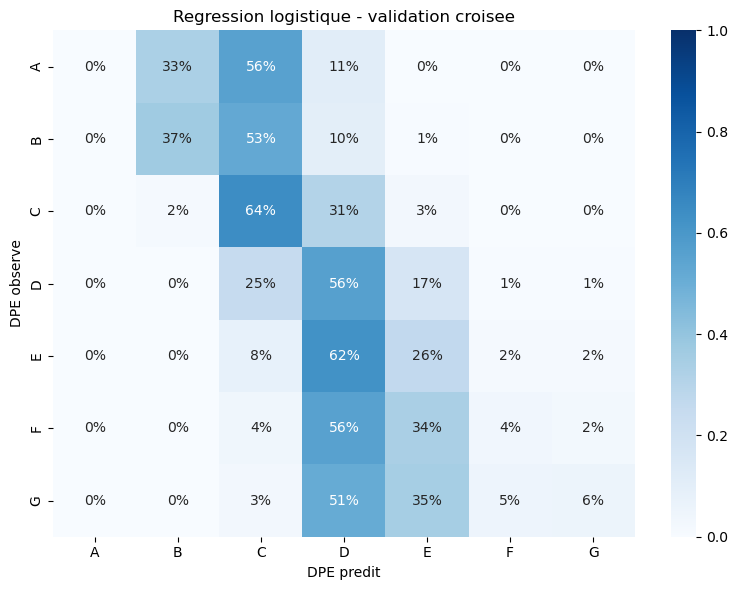

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

matrice_proportions = matrice_confusion.div(
    matrice_confusion.sum(axis=1),
    axis=0
).fillna(0)

plt.figure(figsize=(8, 6))

sns.heatmap(
    matrice_proportions,
    annot=True,
    fmt=".0%",
    cmap="Blues",
    vmin=0,
    vmax=1
)

plt.title("Regression logistique - validation croisee")
plt.xlabel("DPE predit")
plt.ylabel("DPE observe")
plt.tight_layout()
plt.show()

In [28]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV

grille_parametres = {
    "modele__C": [0.01, 0.1, 1, 10, 100],
    "modele__class_weight": [None, "balanced"]
}

recherche_logistique = GridSearchCV(
    estimator=clone(modele_logistique),
    param_grid=grille_parametres,
    scoring={
        "accuracy": "accuracy",
        "balanced_accuracy": "balanced_accuracy",
        "f1_macro": "f1_macro"
    },
    refit="f1_macro",
    cv=plis,
    n_jobs=1,
    verbose=1,
    error_score="raise"
)

recherche_logistique.fit(
    X_train_classification,
    y_train_classification
)

print("Meilleurs paramètres :")
print(recherche_logistique.best_params_)

print("\nMeilleur F1 macro moyen :")
print(round(recherche_logistique.best_score_, 3))

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Meilleurs paramètres :
{'modele__C': 10, 'modele__class_weight': None}

Meilleur F1 macro moyen :
0.313


In [29]:
resultats_recherche = pd.DataFrame(
    recherche_logistique.cv_results_
)

colonnes_resultats = [
    "param_modele__C",
    "param_modele__class_weight",
    "mean_test_accuracy",
    "mean_test_balanced_accuracy",
    "mean_test_f1_macro",
    "std_test_f1_macro"
]

tableau_parametres = (
    resultats_recherche
    .sort_values(
        by="mean_test_f1_macro",
        ascending=False
    )[colonnes_resultats]
)

tableau_parametres.round(3)

,param_modele__C,param_modele__class_weight,mean_test_accuracy,mean_test_balanced_accuracy,mean_test_f1_macro,std_test_f1_macro
6,10.00,None,0.470,0.294,0.313,0.043
8,100.00,None,0.469,0.295,0.302,0.031
4,1.00,None,0.475,0.277,0.288,0.007
9,100.00,balanced,0.353,0.394,0.272,0.003
7,10.00,balanced,0.356,0.394,0.270,0.003
5,1.00,balanced,0.354,0.394,0.268,0.005
3,0.10,balanced,0.344,0.383,0.258,0.005
2,0.10,None,0.474,0.248,0.253,0.021
1,0.01,balanced,0.321,0.374,0.238,0.015
0,0.01,None,0.468,0.202,0.176,0.006


In [30]:
f1_initial = comparaison_classification.loc[
    "Régression logistique",
    "f1_macro"
]

f1_selectionne = recherche_logistique.best_score_

comparaison_optimisation = pd.DataFrame({
    "version": [
        "Initiale",
        "Sélectionnée par GridSearchCV"
    ],
    "f1_macro_cv": [
        f1_initial,
        f1_selectionne
    ]
}).set_index("version")

print(comparaison_optimisation.round(3))

print(
    "\nDifférence de F1 macro :",
    round(f1_selectionne - f1_initial, 3)
)

modele_logistique_selectionne = (
    recherche_logistique.best_estimator_
)

                               f1_macro_cv
version                                   
Initiale                             0.288
Sélectionnée par GridSearchCV        0.313

Différence de F1 macro : 0.025


In [31]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

modele_logistique_selectionne = (
    recherche_logistique.best_estimator_
)

y_pred_test_logistique = modele_logistique_selectionne.predict(
    X_test_classification
)

resultats_test_logistique = pd.DataFrame({
    "accuracy": [
        accuracy_score(
            y_test_classification,
            y_pred_test_logistique
        )
    ],
    "balanced_accuracy": [
        balanced_accuracy_score(
            y_test_classification,
            y_pred_test_logistique
        )
    ],
    "f1_macro": [
        f1_score(
            y_test_classification,
            y_pred_test_logistique,
            labels=classes_valides,
            average="macro",
            zero_division=0
        )
    ]
}, index=["Régression logistique"])

print("Résultats sur le jeu de test :")
print(resultats_test_logistique.round(3))

print("\nRapport de classification :")
print(
    classification_report(
        y_test_classification,
        y_pred_test_logistique,
        labels=classes_valides,
        digits=3,
        zero_division=0
    )
)

Résultats sur le jeu de test :
                       accuracy  balanced_accuracy  f1_macro
Régression logistique     0.517              0.288     0.301

Rapport de classification :
              precision    recall  f1-score   support

           A      0.000     0.000     0.000         2
           B      0.468     0.324     0.383        68
           C      0.663     0.626     0.644      1023
           D      0.480     0.661     0.556      1112
           E      0.347     0.256     0.295       542
           F      0.208     0.032     0.056       156
           G      0.353     0.117     0.175       103

    accuracy                          0.517      3006
   macro avg      0.360     0.288     0.301      3006
weighted avg      0.499     0.517     0.495      3006



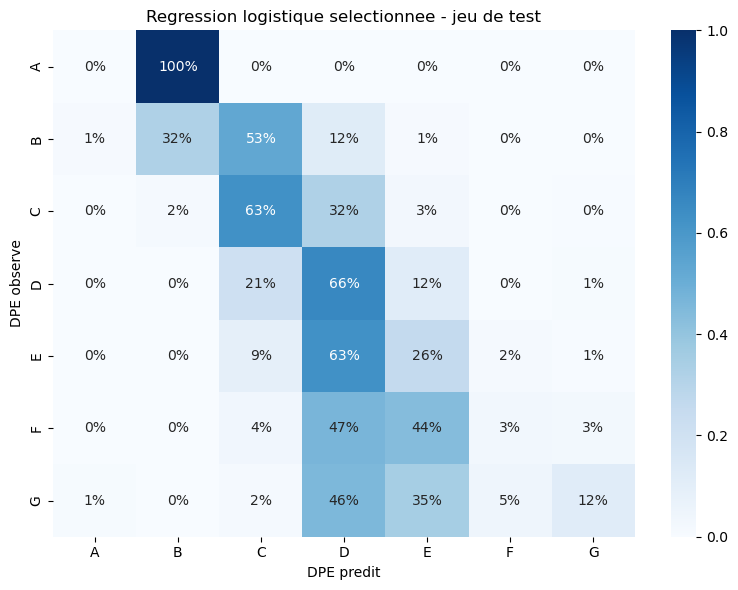

In [32]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

matrice_test_logistique = pd.DataFrame(
    confusion_matrix(
        y_test_classification,
        y_pred_test_logistique,
        labels=classes_valides
    ),
    index=classes_valides,
    columns=classes_valides
)

proportions_test_logistique = matrice_test_logistique.div(
    matrice_test_logistique.sum(axis=1),
    axis=0
).fillna(0)

plt.figure(figsize=(8, 6))

sns.heatmap(
    proportions_test_logistique,
    annot=True,
    fmt=".0%",
    cmap="Blues",
    vmin=0,
    vmax=1
)

plt.title("Regression logistique selectionnee - jeu de test")
plt.xlabel("DPE predit")
plt.ylabel("DPE observe")
plt.tight_layout()
plt.show()

In [33]:
classes_logistique = (
    modele_logistique_selectionne
    .named_steps["modele"]
    .classes_
)

probabilites_test = pd.DataFrame(
    modele_logistique_selectionne.predict_proba(
        X_test_classification
    ),
    index=X_test_classification.index,
    columns=classes_logistique
)

tableau_probabilites = probabilites_test.copy()

tableau_probabilites.insert(
    0,
    "DPE_observe",
    y_test_classification
)

tableau_probabilites.insert(
    1,
    "DPE_predit",
    pd.Series(
        y_pred_test_logistique,
        index=X_test_classification.index
    )
)

tableau_probabilites.head(10).round(3)


,DPE_observe,DPE_predit,A,B,C,D,E,F,G
8,D,D,0.0,0.000,0.455,0.529,0.014,0.002,0.000
15,D,D,0.0,0.001,0.212,0.484,0.252,0.035,0.015
16,E,E,0.0,0.001,0.157,0.274,0.328,0.145,0.094
18,F,C,0.0,0.008,0.307,0.262,0.256,0.103,0.063
19,D,D,0.0,0.000,0.455,0.529,0.014,0.002,0.000
22,C,C,0.0,0.044,0.807,0.148,0.001,0.000,0.000
26,D,D,0.0,0.000,0.038,0.362,0.257,0.193,0.150
30,C,D,0.0,0.014,0.302,0.552,0.128,0.004,0.000
31,D,D,0.0,0.000,0.451,0.532,0.015,0.002,0.000
34,C,C,0.0,0.137,0.788,0.073,0.002,0.000,0.000


In [34]:
preparation_logistique = (
    modele_logistique_selectionne
    .named_steps["preparation"]
)

regression_logistique = (
    modele_logistique_selectionne
    .named_steps["modele"]
)

noms_variables_encodees = (
    preparation_logistique
    .get_feature_names_out()
)

coefficients_logistique = pd.DataFrame(
    regression_logistique.coef_.T,
    index=noms_variables_encodees,
    columns=regression_logistique.classes_
)

coefficients_logistique.loc["Constante"] = (
    regression_logistique.intercept_
)

print(
    "Nombre de variables après encodage :",
    len(noms_variables_encodees)
)

coefficients_logistique.head(20).round(3)

Nombre de variables après encodage : 130


,A,B,C,D,E,F,G
numerique__surface_habitable_logement,0.542,0.733,0.189,0.112,-0.055,-0.300,-1.220
numerique__nombre_niveau_logement,-0.507,0.222,0.135,0.100,0.073,-0.080,0.056
numerique__surface_climatisee,-0.860,0.065,0.101,0.131,0.157,0.186,0.221
categoriel__code_postal_ban_69001,-0.783,1.132,0.136,-0.167,-0.189,0.002,-0.131
categoriel__code_postal_ban_69002,-1.337,0.576,0.372,0.447,0.081,0.025,-0.163
categoriel__code_postal_ban_69003,1.702,-0.332,-0.063,-0.124,-0.170,-0.531,-0.481
categoriel__code_postal_ban_69004,-0.389,-1.752,0.422,0.565,0.408,0.252,0.494
categoriel__code_postal_ban_69005,-0.678,-0.038,-0.019,0.178,0.193,0.188,0.175
categoriel__code_postal_ban_69006,1.982,-0.182,-0.322,-0.252,-0.468,-0.362,-0.397
categoriel__code_postal_ban_69007,1.346,0.453,-0.232,-0.345,-0.286,-0.500,-0.435


In [35]:
donnees_communes = df_projet.copy()

donnees_communes.insert(
    0,
    "numero_dpe",
    df_clean.loc[df_projet.index, "numero_dpe"]
)

donnees_communes["groupe_batiment"] = groupes.reindex(
    donnees_communes.index
)

donnees_communes["partition"] = ""

donnees_communes.loc[
    donnees_communes.index.isin(indices_train),
    "partition"
] = "train"

donnees_communes.loc[
    donnees_communes.index.isin(indices_test),
    "partition"
] = "test"

if donnees_communes["partition"].eq("").any():
    raise ValueError("Certaines lignes n'ont pas de partition.")

if donnees_communes["groupe_batiment"].isna().any():
    raise ValueError("Certains groupes sont manquants.")

donnees_communes.to_csv(
    "dpe_donnees_communes.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Fichier enregistré : dpe_donnees_communes.csv")
print(donnees_communes["partition"].value_counts())

Fichier enregistré : dpe_donnees_communes.csv
partition
train    6915
test     3006
Name: count, dtype: int64


In [37]:
import numpy as np
import pandas as pd

from sklearn.metrics import accuracy_score, f1_score

y_pred_test_logistique = modele_logistique_selectionne.predict(
    X_test_classification
)

ordre_classes = {
    classe: position
    for position, classe in enumerate("ABCDEFG")
}

classes_observees = y_test_classification.map(
    ordre_classes
).to_numpy()

classes_predites = pd.Series(
    y_pred_test_logistique
).map(ordre_classes).to_numpy()

bilan_classification = pd.DataFrame([{
    "Modèle": "Régression logistique",
    "Accuracy": accuracy_score(
        y_test_classification,
        y_pred_test_logistique
    ),
    "Accuracy ±1 classe": np.mean(
        np.abs(classes_observees - classes_predites) <= 1
    ),
    "F1 macro": f1_score(
        y_test_classification,
        y_pred_test_logistique,
        labels=list("ABCDEFG"),
        average="macro",
        zero_division=0
    ),
    "F1 weighted": f1_score(
        y_test_classification,
        y_pred_test_logistique,
        labels=list("ABCDEFG"),
        average="weighted",
        zero_division=0
    )
}])

bilan_classification.to_csv(
    "classification_resultats_finaux.csv",
    index=False,
    encoding="utf-8-sig"
)

display(bilan_classification.round(3))

print("Fichier enregistré : classification_resultats_finaux.csv")

,Modèle,Accuracy,Accuracy ±1 classe,F1 macro,F1 weighted
0,Régression logistique,0.517,0.908,0.301,0.495


Fichier enregistré : classification_resultats_finaux.csv


In [38]:
from pathlib import Path

chemin_classification = Path(
    "classification_resultats_finaux.csv"
).resolve()

print(chemin_classification)
print("Existe :", chemin_classification.exists())

/Users/jingxilian/Desktop/projet_dpe/classification_resultats_finaux.csv
Existe : True
